# Chapter 2: Simple Linear Regression excercise

In [98]:
%reset
low_memory=False

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

## 2.1 Introduction & Motivation

Now that you have learned about linear regression, how to use it and how to evaluate, it's time to put this into practice!
We will be looking at a dataset containing data about advertisement budget and sales. We will be trying to see if there are any correlations and if we can predict these.

## 2.2 Problem setting

A company called Contoso is spending a certain amount of budget on advertising each month. They are keeping all this data in a single dataset which displays sales (in thousands of units) for a particular product as well as advertising budgets (in thousands of dollars) for TV, radio, and newspaper media that month.

## 2.3 Model

Go to canvas and donload the file "Advertising.csv" from module 2. This data contains the required dataset.

In [99]:
df = pd.read_csv("Advertising.csv")
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


##### Question 1: Have a look at the columns and data of this dataset. What variables would you want to predict? What variables would you like to base your prediction on?

##### Question 2: Without plotting the data on a graph, think about the real-life facts behind this data. Would you expect linear regression make sense for the required predictions? Why (not)?

### Antwoorden (Q1–Q2)
**Q1.** We willen **sales** (verkoop) voorspellen. Dat is de *target* (y).
De *features* (X) zijn de advertentiebudgetten: **TV**, **radio**, **newspaper** (en eventueel de som `total_spent`).

**Q2.** *Logistics regression* is bedoeld voor een **categorische** target (bv. ja/nee). Hier is `sales` **continu**, dus logistic regression is niet geschikt. Een (multiple) **linear regression** past wel bij dit probleem.

Before we train this new model, we first want to create a column where all our information is stored. We will call this column 'total_spent'.

Since we are working with an actual dataset, we also want to split our data. in a train and a test set. This ensure we can properly evaluate our model and test in on data it has never seen before.

In [100]:
df['total_spent'] = df['TV'] + df['radio'] + df['newspaper']

X = df['total_spent'].to_numpy().reshape(-1, 1)
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

##### Question 3: Notice the two parameters called "test_size" and "random_state". "test_size" is required while "random_state" is an optional parameter. Read the sklearn documentation to know more about them. What do these variables mean? Are there any contraineds on them or can you put whatever you want? What would happen if you change the numers? What would happen if you drop the "random_state" parameter? Can you think of any scenario's where you would do so?

### Antwoord (Q3)
- `test_size`: het aandeel (float tussen 0 en 1) of aantal (int) observaties dat naar de **test set** gaat.
- `random_state`: seed voor de random split. Met dezelfde seed krijg je **reproduceerbare** resultaten.

Als je `test_size` verandert, veranderen de grootte van train/test en dus ook de parameters en scores. Als je `random_state` weglaat, wordt de split elke run anders, waardoor je resultaten kunnen verschillen.

Now that you have prepared your data it's time to train the model. Make sure to only use the training data!

In [101]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


##### Question 4:  Plot a graph to show the amount of sales in function of the total amount spent on advertising. Draw a line using Beta 0 and Beta 1 to show our model. Does this confirm/deny your earlier assumptions about whether or not to choose linear regression?

Text(0, 0.5, 'Y')

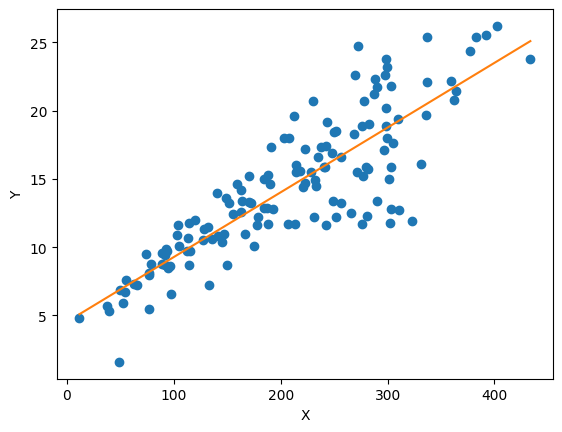

In [102]:
min_pt = X_train.min()*model.coef_[0]+model.intercept_
max_pt = X_train.max()*model.coef_[0]+model.intercept_
plt.plot(X_train,y_train,'o')
plt.plot([X_train.min(),X_train.max()],[min_pt,max_pt])
plt.xlabel("X")
plt.ylabel("Y")

### Antwoord (Q4)
De punten liggen duidelijk rond een stijgende lijn: meer budget -> gemiddeld meer sales. Dat ondersteunt de keuze voor **linear regression**.

## 2.4 Model Evaluation

Now it's time to evaluate this model! To do so, calculate the $R^2$ value of our model.

##### Question 5: Interpret the $R^2$ score. Is our model any good?

In [103]:
model.score(X_train,y_train)

0.73228658313651

### Antwoord (Q5)
`R^2` geeft aan welk deel van de variantie in `sales` verklaard wordt door `total_spent`.
Hier is `R^2` behoorlijk hoog (rond 0.7–0.8), dus het model verklaart een groot deel van de variatie, maar zeker niet alles.

The $R^2$ value is not the only value that evaluates our model. Another interesting value to look at is the $MSE$.

##### Question 6: Calculate the MSE. Remember that we kept some test data on the side exactly for this purpose!

In [105]:
y_pred = model.predict(X_test)
mse_test = mean_squared_error(y_test, y_pred)
mse_test

5.921660160912178

##### Question 7: Calculate the MSE but this time on training data. Compare both values. Is this what you would expect? Can you explain the result?

In [106]:
y_pred_train = model.predict(X_train)
mse_train = mean_squared_error(y_train, y_pred_train)
mse_train, mse_test

(7.045187801076913, 5.921660160912178)

### Antwoord (Q7)
Meestal verwacht je `MSE_train` ≤ `MSE_test` (want het model is gefit op train). Door de toevallige split en ruis kan het soms omgekeerd uitvallen, zeker bij kleinere datasets. Belangrijk is vooral dat ze in dezelfde orde van grootte liggen en dat `MSE_test` niet extreem veel groter is.

## 2.5 Exercises

##### Question 1: See section 2.3
##### Question 2: See section 2.3
##### Question 3: See section 2.3
##### Question 4: See section 2.3
##### Question 5: See section 2.4
##### Question 6: See section 2.4
##### Question 7: See section 2.4

##### Question 8: Our next ad campaign will have a total spend of 236k on advertisement, how many units could we expect to sell as a result of this?**

In [107]:
pred_236 = model.predict([[236]])
pred_236

array([15.72459273])

##### Question 9: In our current model we have created a new table for the total amount of advertisement. However, it is likely that The seperate budget columns have a different influence on our model. Create a model for each budget column and compare their performance using $R^2$ and the MSE on test data. What do you notice?


Feature: TV
R2 train: 0.5969856732137406
R2 test : 0.6345141851817351
MSE test: 10.318455423013349
Intercept: 7.177057802578858


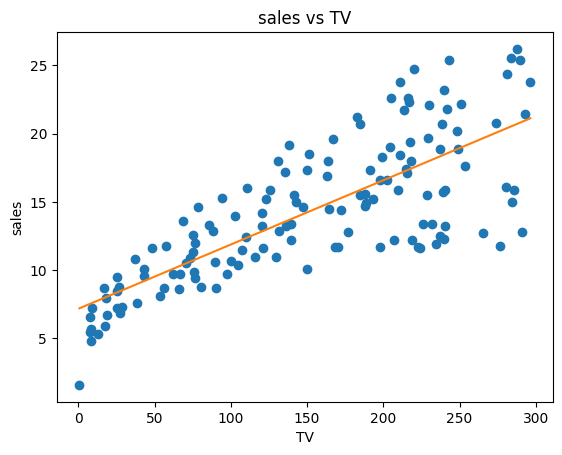


Feature: radio
R2 train: 0.34969819733576046
R2 test : 0.2700871648992673
MSE test: 20.60701878516741
Intercept: 9.49438088922263


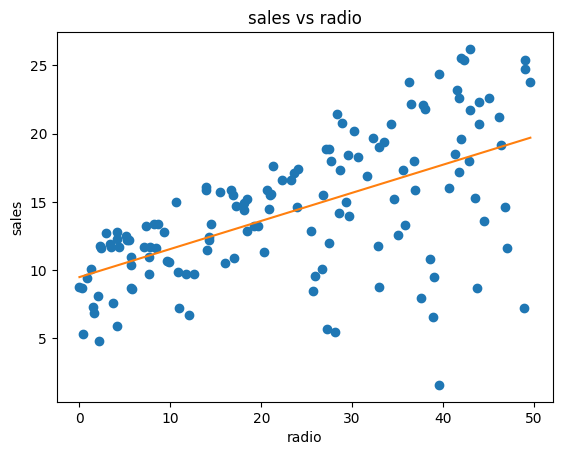


Feature: newspaper
R2 train: 0.06487017361800451
R2 test : -0.007339074182552308
MSE test: 28.43936183400341
Intercept: 12.413083366368108


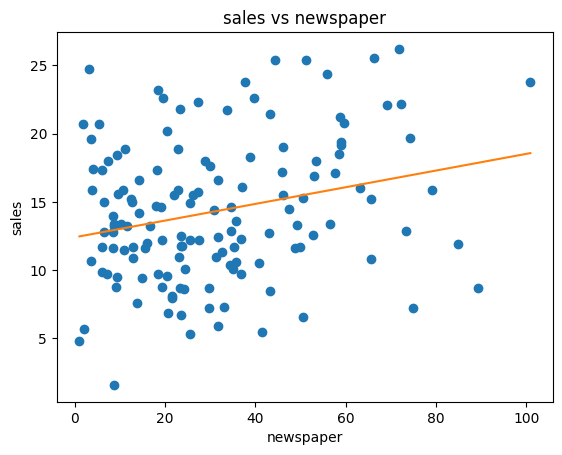

,feature,beta0(intercept),R2_train,R2_test,MSE_test
0,TV,7.177058,0.596986,0.634514,10.318455
1,radio,9.494381,0.349698,0.270087,20.607019
2,newspaper,12.413083,0.064870,-0.007339,28.439362


In [108]:
# Voor 1 specifieke unit
# X = df['TV'].to_numpy().reshape(-1,1)
# y = df['sales']

# X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=101)

# model = LinearRegression()
# model.fit(X_train,y_train)

# print('R2', model.score(X_train,y_train))
# y_pred = model.predict(X_test)
# print('MSE',mean_squared_error(y_pred,y_test))

# min_pt = X_train.min()*model.coef_[0]+model.intercept_
# max_pt = X_train.max()*model.coef_[0]+model.intercept_
# plt.plot(X_train,y_train,'o')
# plt.plot([X_train.min(),X_train.max()],[min_pt,max_pt])
# plt.xlabel("X")
# plt.ylabel("Y")

# Voor alle units
results = []
for feat in ['TV', 'radio', 'newspaper']:
    X = df[feat].to_numpy().reshape(-1, 1)
    y = df['sales']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

    model = LinearRegression()
    model.fit(X_train, y_train)

    r2_train = model.score(X_train, y_train)
    r2_test = model.score(X_test, y_test)

    y_pred = model.predict(X_test)
    mse_test = mean_squared_error(y_test, y_pred)

    print(f'\nFeature: {feat}')
    print('R2 train:', r2_train)
    print('R2 test :', r2_test)
    print('MSE test:', mse_test)
    print('Intercept:', model.intercept_)

    results.append([feat, model.intercept_, r2_train, r2_test, mse_test])

    min_pt = X_train.min() * model.coef_[0] + model.intercept_
    max_pt = X_train.max() * model.coef_[0] + model.intercept_

    plt.figure()
    plt.plot(X_train, y_train, 'o')
    plt.plot([X_train.min(), X_train.max()], [min_pt, max_pt])
    plt.xlabel(feat)
    plt.ylabel("sales")
    plt.title(f"sales vs {feat}")
    plt.show()

single_df = pd.DataFrame(results,columns=['feature', 'beta0(intercept)', 'R2_train', 'R2_test', 'MSE_test'])
single_df

### Antwoord (Q9)
Je ziet typisch dat **TV** het sterkst voorspelt, **radio** middelmatig en **newspaper** bijna niet (lage `R^2`, hoge MSE). De som `total_spent` doet het al beter dan elk kanaal apart, maar we verliezen informatie doordat we de kanalen samenvoegen.

##### Question 10: WHen we calculate the total budget, we technically have all the data in one column. However, it might be possible that there is extra value to gain when keeping the columns seperate. Build a single model with three distinct features (TV, Radio and Newspaper). Plot the model and evaluate it using $R^2$. Is this an improvement? Test the model on test data and calculate the MSE. Compare this to our current model. Is there an improvement here?

In [109]:
X3 = df[['TV','radio','newspaper']]
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(X3, y, test_size=0.3, random_state=101)

model3 = LinearRegression()
model3.fit(X_train, y_train)

print('r2_train:', model3.score(X_train, y_train))
print('mse_test:', mean_squared_error(y_test, model3.predict(X_test)))


r2_train: 0.8856665510409361
mse_test: 2.2987166978863782


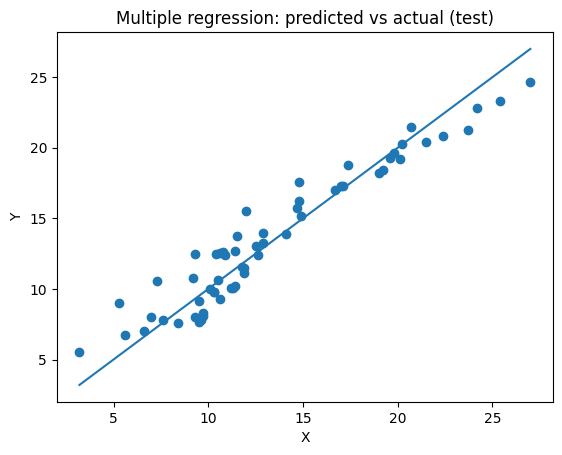

In [110]:
# Plot
yhat = model3.predict(X_test)
plt.scatter(y_test, yhat)
line = np.linspace(y_test.min(), y_test.max(), 100)
plt.plot(line, line)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Multiple regression: predicted vs actual (test)')
plt.show()

### Antwoord (Q10)
Dit is meestal een **verbetering**: we laten het model per kanaal een eigen invloed leren. Je ziet een hogere `R^2` en een lagere MSE op test t.o.v. het `total_spent`-model.

##### Question 11: Show the coefficients of the newly trained models. How many are there? Why is this? Plot the function using Beta 0 and Beta 1 on a graph using 'model.predict'. Can you explain the results? How would you merge this into a single function?

In [111]:
coef_df = pd.Series(model3.coef_, index=['TV','radio','newspaper'])
print('Intercept:',model3.intercept_)
coef_df

Intercept: 3.151526768070651


TV           0.044696
radio        0.187566
newspaper   -0.000323
dtype: float64

### Antwoord (Q11)
Er zijn **3** slopes (één per feature) + **1** intercept.

Je kan dit niet als één simpele 2D-lijn plotten zonder 1 of 2 variabelen vast te zetten. Daarom is een *predicted vs actual* plot vaak het duidelijkst.


##### Question 12: Our next ad campaign will have a total spend of 149k on TV, 22k on Radio, and 12k on Newspaper Ads, how many units could we expect to sell as a result of this?

In [114]:
pred_campaign = model3.predict(pd.DataFrame({'TV':[149], 'radio':[22], 'newspaper':[12]}))
print(pred_campaign)

# OF

# pred = model3.predict([[149,22,12]])
# pred

[13.93380216]
